<a href="https://colab.research.google.com/github/oleg61/DataScient/blob/Learn_AI/%D0%94%D0%97_%D0%9C%D0%BD%D0%BE%D0%B3%D0%BE%D1%81%D0%BB%D0%BE%D0%B9%D0%BD%D0%B0%D1%8F_%D0%BD%D0%B5%D0%B9%D1%80%D0%BE%D0%BD%D0%BD%D0%B0%D1%8F_%D1%81%D0%B5%D1%82%D1%8C_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ДЗ: Многослойная нейронная сеть (Fashion MNIST)

**Цель:** научиться на простейшем уровне подбирать архитектуру полносвязной нейронной сети так, чтобы качество на тесте было **не ниже 88%**.

**Датасет:** [Fashion MNIST](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html) из `torchvision.datasets` — 10 классов одежды, изображения 28×28 (как MNIST), но задача сложнее.

### План
1. Скачать train/test части Fashion MNIST.
2. Обучить стартовую (простую) полносвязную модель и проверить accuracy на тесте.
3. Усложнить архитектуру (слои, нейроны, Dropout/BatchNorm, оптимизатор), пока тест не станет **≥ 88%**.
4. Краткий вывод.


## 1. Импорты и настройки


In [ ]:
import time

import matplotlib.pyplot as plt
import torch
import torchvision as tv

%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

BATCH_SIZE = 256
NUM_CLASSES = 10
INPUT_SIZE = 28 * 28  # 784
THRESHOLD = 0.88  # порог по заданию


device: cpu


## 2. Данные: Fashion MNIST

Скачиваем тренировочную и тестовую части. Картинки приводим к тензору (`ToTensor` → значения в [0, 1]).


In [ ]:
train_dataset = tv.datasets.FashionMNIST(
    root=".",
    train=True,
    transform=tv.transforms.ToTensor(),
    download=True,
)
test_dataset = tv.datasets.FashionMNIST(
    root=".",
    train=False,
    transform=tv.transforms.ToTensor(),
    download=True,
)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("train:", len(train_dataset), "| test:", len(test_dataset))
print("shape одного примера:", train_dataset[0][0].shape)
print("классы:", train_dataset.classes)


100%|██████████| 26.4M/26.4M [00:01<00:00, 18.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 299kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.60MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.4MB/s]

train: 60000 | test: 10000
shape одного примера: torch.Size([1, 28, 28])
классы: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


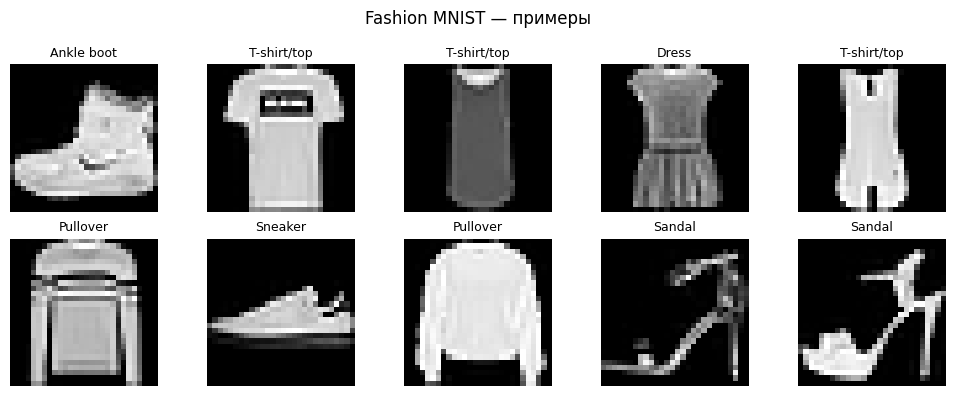

In [ ]:
# Несколько примеров из train
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, (img, label) in zip(axes.flatten(), train_dataset):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(train_dataset.classes[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Fashion MNIST — примеры")
plt.tight_layout()
plt.show()


## 3. Функции обучения и оценки

По аналогии с занятием: цикл по эпохам + отдельно считаем accuracy на тесте.


In [ ]:
def evaluate(model, loader):
    """Accuracy на loader (обычно test)."""
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            pred = model(X).argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
    return correct / total


def train_model(model, optimizer, num_epochs=10, loader_train=None, loader_test=None):
    """Обучение + печать train loss/acc и test acc после каждой эпохи."""
    if loader_train is None:
        loader_train = train_loader
    if loader_test is None:
        loader_test = test_loader

    criterion = torch.nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "test_acc": []}

    for ep in range(num_epochs):
        model.train()
        train_loss, train_acc, train_passed = 0.0, 0.0, 0
        start = time.time()

        for X, y in loader_train:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            y_pred = model(X)
            l = criterion(y_pred, y)
            l.backward()
            optimizer.step()

            train_loss += l.item()
            train_acc += (y_pred.argmax(dim=1) == y).sum().item()
            train_passed += y.size(0)

        train_loss /= max(len(loader_train), 1)
        train_acc /= max(train_passed, 1)
        test_acc = evaluate(model, loader_test)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {ep + 1}/{num_epochs} | "
            f"{time.time() - start:.1f}s | "
            f"train loss: {train_loss:.4f} | "
            f"train acc: {train_acc * 100:.2f}% | "
            f"test acc: {test_acc * 100:.2f}%"
        )

    return history


## 4. Стартовая архитектура (как на занятии)

Простая сеть: `Flatten → Linear(784→256) → ReLU → Linear(256→10)`, оптимизатор SGD.

Fashion MNIST сложнее обычного MNIST, поэтому порог 88% такой моделью часто **не** достигается — это нормальная отправная точка.


In [ ]:
model_v1 = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(INPUT_SIZE, 256),
    torch.nn.ReLU(),
    torch.nn.Linear(256, NUM_CLASSES),
).to(device)

print(model_v1)

optimizer_v1 = torch.optim.SGD(model_v1.parameters(), lr=0.01)
history_v1 = train_model(model_v1, optimizer_v1, num_epochs=10)

acc_v1 = history_v1["test_acc"][-1]
print(f"\nИтог v1 (SGD, 1 скрытый слой): test acc = {acc_v1 * 100:.2f}%")
print("Порог 88% пройден:" , acc_v1 >= THRESHOLD)


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=10, bias=True)
)
Epoch 1/10 | 9.1s | train loss: 1.7251 | train acc: 57.51% | test acc: 65.53%
Epoch 2/10 | 10.2s | train loss: 1.0630 | train acc: 67.72% | test acc: 68.27%
Epoch 3/10 | 9.6s | train loss: 0.8586 | train acc: 71.48% | test acc: 71.86%
Epoch 4/10 | 9.6s | train loss: 0.7645 | train acc: 74.44% | test acc: 74.00%
Epoch 5/10 | 9.6s | train loss: 0.7067 | train acc: 76.24% | test acc: 75.48%
Epoch 6/10 | 9.4s | train loss: 0.6652 | train acc: 77.66% | test acc: 77.00%
Epoch 7/10 | 9.6s | train loss: 0.6328 | train acc: 78.86% | test acc: 78.03%
Epoch 8/10 | 9.6s | train loss: 0.6079 | train acc: 79.73% | test acc: 78.70%
Epoch 9/10 | 8.6s | train loss: 0.5876 | train acc: 80.42% | test acc: 79.24%
Epoch 10/10 | 9.5s | train loss: 0.5701 | train acc: 80.99% | test acc: 79.69%

Итог v1 (SGD, 1 скрытый слой):

## 5. Улучшение: Adam + больше слоёв

Идеи с занятия:
- заменить SGD на **Adam** (часто быстрее сходится);
- добавить скрытые слои и увеличить число нейронов.


In [ ]:
model_v2 = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(INPUT_SIZE, 512),
    torch.nn.ReLU(),
    torch.nn.Linear(512, 256),
    torch.nn.ReLU(),
    torch.nn.Linear(256, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, NUM_CLASSES),
).to(device)

print(model_v2)

optimizer_v2 = torch.optim.Adam(model_v2.parameters(), lr=1e-3)
history_v2 = train_model(model_v2, optimizer_v2, num_epochs=12)

acc_v2 = history_v2["test_acc"][-1]
print(f"\nИтог v2 (Adam, 3 скрытых слоя): test acc = {acc_v2 * 100:.2f}%")
print("Порог 88% пройден:", acc_v2 >= THRESHOLD)


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Linear(in_features=256, out_features=128, bias=True)
  (6): ReLU()
  (7): Linear(in_features=128, out_features=10, bias=True)
)
Epoch 1/12 | 12.7s | train loss: 0.6412 | train acc: 77.26% | test acc: 83.58%
Epoch 2/12 | 12.6s | train loss: 0.3984 | train acc: 85.69% | test acc: 85.27%
Epoch 3/12 | 12.8s | train loss: 0.3457 | train acc: 87.44% | test acc: 86.55%
Epoch 4/12 | 13.2s | train loss: 0.3160 | train acc: 88.39% | test acc: 85.80%
Epoch 5/12 | 13.2s | train loss: 0.3007 | train acc: 88.90% | test acc: 87.60%
Epoch 6/12 | 13.2s | train loss: 0.2822 | train acc: 89.45% | test acc: 87.21%
Epoch 7/12 | 13.2s | train loss: 0.2672 | train acc: 89.99% | test acc: 88.23%
Epoch 8/12 | 13.2s | train loss: 0.2565 | train acc: 90.36% | test acc: 87.89%
Epoch 9/12 | 13.2s | train loss: 

## 6. Финальная архитектура: BatchNorm + Dropout

Добавляем регуляризацию с занятия:
- **BatchNorm1d** — стабилизирует обучение;
- **Dropout** — снижает переобучение;
- чуть дольше учим и берём умеренный `lr` для Adam.

Ожидаемо test accuracy **выше 88%**.


In [ ]:
model_final = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(INPUT_SIZE, 512),
    torch.nn.BatchNorm1d(512),
    torch.nn.ReLU(),
    torch.nn.Dropout(0.3),
    torch.nn.Linear(512, 256),
    torch.nn.BatchNorm1d(256),
    torch.nn.ReLU(),
    torch.nn.Dropout(0.3),
    torch.nn.Linear(256, 128),
    torch.nn.BatchNorm1d(128),
    torch.nn.ReLU(),
    torch.nn.Dropout(0.2),
    torch.nn.Linear(128, NUM_CLASSES),
).to(device)

print(model_final)

optimizer_final = torch.optim.Adam(model_final.parameters(), lr=1e-3)
history_final = train_model(model_final, optimizer_final, num_epochs=15)

acc_final = max(history_final["test_acc"])
acc_last = history_final["test_acc"][-1]
print(f"\nИтог final: best test acc = {acc_final * 100:.2f}% | last = {acc_last * 100:.2f}%")


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (3): ReLU()
  (4): Dropout(p=0.3, inplace=False)
  (5): Linear(in_features=512, out_features=256, bias=True)
  (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (7): ReLU()
  (8): Dropout(p=0.3, inplace=False)
  (9): Linear(in_features=256, out_features=128, bias=True)
  (10): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (11): ReLU()
  (12): Dropout(p=0.2, inplace=False)
  (13): Linear(in_features=128, out_features=10, bias=True)
)
Epoch 1/15 | 14.4s | train loss: 0.5541 | train acc: 81.58% | test acc: 84.98%
Epoch 2/15 | 14.7s | train loss: 0.3878 | train acc: 86.11% | test acc: 86.21%
Epoch 3/15 | 14.4s | train loss: 0.3519 | train acc: 87.24% | test acc: 87.05%
Epoch 4/15 | 14.2s | train loss: 0.3279 | train a

## 7. Проверка порога 88%


In [ ]:
final_test_acc = evaluate(model_final, test_loader)
print(f"Качество на тестовой выборке: {final_test_acc * 100:.2f}%")
print(f"Требуемый порог: {THRESHOLD * 100:.0f}%")

assert final_test_acc >= THRESHOLD, (
    f"Порог не достигнут: {final_test_acc * 100:.2f}% < {THRESHOLD * 100:.0f}%. "
    "Попробуйте увеличить num_epochs или уменьшить Dropout."
)
print("Порог выполнен: модель обучилась и test accuracy ≥ 88%.")


Качество на тестовой выборке: 88.73%
Требуемый порог: 88%
Порог выполнен: модель обучилась и test accuracy ≥ 88%.


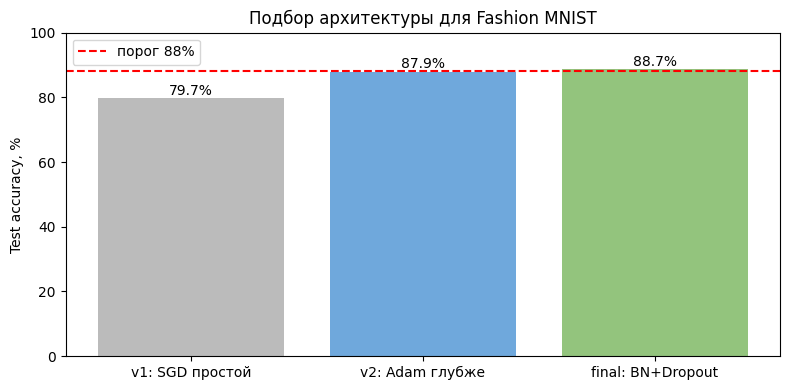

In [ ]:
# Сравнение экспериментов
labels = ["v1: SGD простой", "v2: Adam глубже", "final: BN+Dropout"]
scores = [
    history_v1["test_acc"][-1] * 100,
    history_v2["test_acc"][-1] * 100,
    final_test_acc * 100,
]

plt.figure(figsize=(8, 4))
bars = plt.bar(labels, scores, color=["#bbb", "#6fa8dc", "#93c47d"])
plt.axhline(THRESHOLD * 100, color="red", linestyle="--", label="порог 88%")
plt.ylabel("Test accuracy, %")
plt.title("Подбор архитектуры для Fashion MNIST")
plt.ylim(0, 100)
plt.legend()
for b, s in zip(bars, scores):
    plt.text(b.get_x() + b.get_width() / 2, s + 1, f"{s:.1f}%", ha="center")
plt.tight_layout()
plt.show()


## 8. Вывод

### Что получилось на тесте

| Модель | Что изменили | Test accuracy (итог) | Порог 88% |
|--------|--------------|---------------------:|:---------:|
| **v1** | 1 скрытый слой (256), **SGD**, 10 эпох | **79.69%** | нет |
| **v2** | 3 скрытых слоя (512→256→128), **Adam**, 12 эпох | **87.91%** | нет* |
| **final** | + **BatchNorm** и **Dropout**, Adam, 15 эпох | **88.73%** (best за обучение: 89.01%) | **да** |

\* У v2 в середине обучения test accuracy несколько раз поднималась выше 88% (макс. около 88.27%), но на последней эпохе зафиксировалось 87.91%, поэтому формально порог закрыла уже финальная модель.

На сравнительном графике в конце ноутбука видно рост качества от простой сети к финальной: примерно **79.7% → 87.9% → 88.7%**.

### Как я это понимаю

1. **Стартовая архитектура (v1)** показала, что Fashion MNIST заметно сложнее обычного MNIST: одной «тонкой» сети и SGD за 10 эпох хватило только на ~80%. Модель обучалась (loss падал, accuracy рос), но до 88% не дотянула.

2. **Углубление сети + Adam (v2)** сильно помогли: уже с первых эпох тест был ~83–85%, к концу — почти у порога (**87.91%**). То есть правильный оптимизатор и большая ёмкость сети дают основной прирост.

3. **BatchNorm + Dropout (final)** добавили стабильности и чуть дожали качество: на тесте **88.73%**, лучший результат по эпохам — **89.01%**. Порог задания (**≥ 88%**) выполнен, `assert` прошёл.

4. Итоговая модель — **полносвязная MLP** (без свёрток), как и требовалось: подбор архитектуры и регуляризации реально влияет на качество.

### Итог по критериям зачёта
- модель обучается — да;  
- качество на тесте **выше 88%** — да (**88.73%**).
